Checking input files

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient101_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient101_frame14.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient102_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient102_frame13.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient103_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient103_frame11.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient104_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient104_frame11.h5
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient105_frame01.h5
/kaggle/input/datasets/anhoangvo/acdc

Patient 001 to 100 have individual frame h5 files and also individual slice h5 files for each frame file, patient 101 to 150 only seem to have frame files not individual slice files

In [12]:
!pip install scikit-image

In [ ]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
import os
import glob
import re
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from skimage.measure import marching_cubes
from scipy.ndimage import gaussian_filter, distance_transform_edt



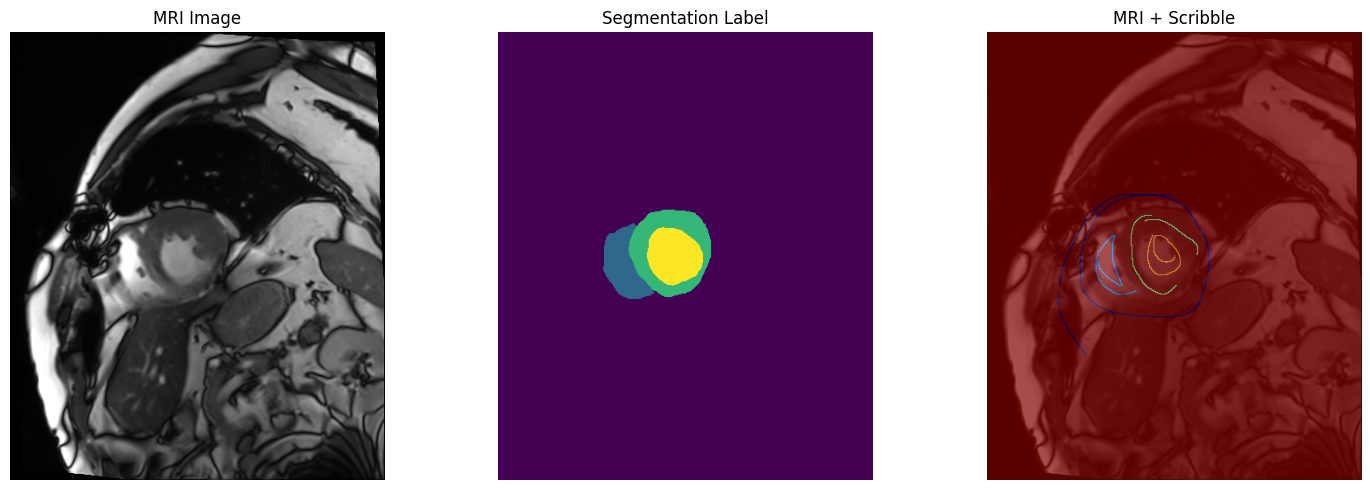

In [2]:
file_path = "/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_slices/patient057_frame09_slice_3.h5"

with h5py.File(file_path, "r") as f:
    image = f["image"][:]
    label = f["label"][:]
    scribble = f["scribble"][:]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("MRI Image")

axes[1].imshow(label, cmap="viridis")
axes[1].set_title("Segmentation Label")

axes[2].imshow(image, cmap="gray")
axes[2].imshow(scribble, cmap="jet", alpha=0.7)
axes[2].set_title("MRI + Scribble")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Seeing structure of the data files

In [3]:
DATA_DIR = "/kaggle/input"

for root, dirs, files in os.walk(DATA_DIR):
    print(root)
    print(files[:10])

/kaggle/input
[]
/kaggle/input/datasets
[]
/kaggle/input/datasets/anhoangvo
[]
/kaggle/input/datasets/anhoangvo/acdc-dataset
[]
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed
[]
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes
['patient101_frame01.h5', 'patient101_frame14.h5', 'patient102_frame01.h5', 'patient102_frame13.h5', 'patient103_frame01.h5', 'patient103_frame11.h5', 'patient104_frame01.h5', 'patient104_frame11.h5', 'patient105_frame01.h5', 'patient105_frame10.h5']
/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_slices
['patient001_frame01_slice_0.h5', 'patient001_frame01_slice_1.h5', 'patient001_frame01_slice_2(1).h5', 'patient001_frame01_slice_2.h5', 'patient001_frame01_slice_3(1).h5', 'patient001_frame01_slice_3.h5', 'patient001_frame01_slice_4(1).h5', 'patient001_frame01_slice_4.h5', 'patient001_frame01_slice_5(1).h5', 'patient001_frame01_slice_5.h5']
/kaggle/input/datasets/anhoangvo/acdc-dat

In [4]:
h5_files = glob.glob(
    "/kaggle/input/**/*.h5",
    recursive=True
)

print("Total H5 files:", len(h5_files))
print(h5_files[:10])

Total H5 files: 2212
['/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient101_frame01.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient101_frame14.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient102_frame01.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient102_frame13.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient103_frame01.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient103_frame11.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient104_frame01.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient104_frame11.h5', '/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient105_f

In [5]:
file_path = h5_files[0]

with h5py.File(file_path, "r") as f:
    print("File:", file_path)
    print("Keys:", list(f.keys()))

    for key in f.keys():
        arr = f[key][:]

        print(f"\n{key}")
        print("Shape:", arr.shape)
        print("Data type:", arr.dtype)
        print("Unique values:", np.unique(arr)[:20])

File: /kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_testing_volumes/patient101_frame01.h5
Keys: ['image', 'label']

image
Shape: (10, 256, 232)
Data type: float32
Unique values: [0.         0.00653687 0.01307373 0.0196106  0.02614746 0.03268433
 0.03922119 0.04575806 0.05229492 0.05883179 0.06536866 0.07190552
 0.07844239 0.08497925 0.09151612 0.09805299 0.10458985 0.11112671
 0.11766358 0.12420045]

label
Shape: (10, 256, 232)
Data type: uint8
Unique values: [0 1 2 3]


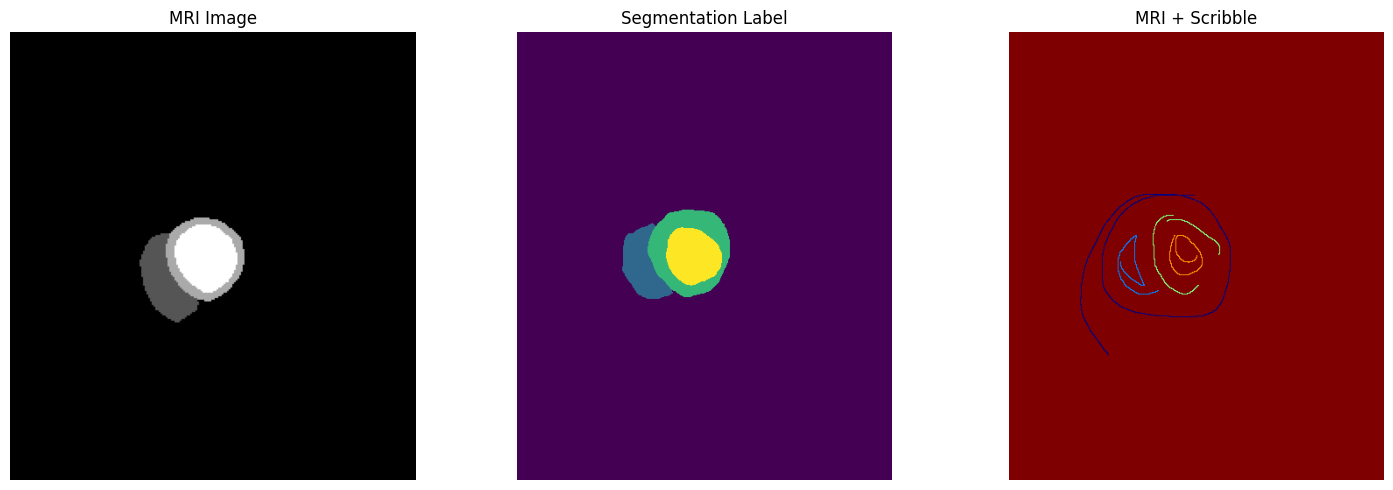

In [6]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(arr[3], cmap="gray")
axes[0].set_title("MRI Image")

axes[1].imshow(label, cmap="viridis")
axes[1].set_title("Segmentation Label")

axes[2].imshow(arr[3], cmap="gray")
axes[2].imshow(scribble, cmap="jet", alpha=1)
axes[2].set_title("MRI + Scribble")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
def plot_patient_3d_interactive(
    patient_number,
    dataset_path="/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes",
    max_points_per_class=15000,
    depth_scale=0.65
):

    patient_id = f"patient{str(patient_number)}"

    pattern = os.path.join(dataset_path, f"{patient_id}_frame*.h5")
    frame_files = glob.glob(pattern)

    def get_frame_number(filepath):
        match = re.search(r"frame(\d+)", os.path.basename(filepath))
        return int(match.group(1)) if match else -1

    frame_files = sorted(frame_files, key=get_frame_number)

    if not frame_files:
        print(f"No frames found for {patient_id}")
        return

    n_frames = len(frame_files)

    # One interactive 3D subplot per frame
    fig = make_subplots(
        rows=1,
        cols=n_frames,
        specs=[[{"type": "scene"} for _ in range(n_frames)]],
        subplot_titles=[
            f"Frame {get_frame_number(f):02d}"
            for f in frame_files
        ]
    )

    colors = {
        1: "red",
        2: "limegreen",
        3: "blue"
    }

    class_names = {
        1: "RV",
        2: "Myocardium",
        3: "LV"
    }

    for col, filepath in enumerate(frame_files, start=1):

        with h5py.File(filepath, "r") as f:
            label = f["label"][:]

        # label shape: (slices, height, width)
        n_slices, height, width = label.shape

        for class_id in [1, 2, 3]:

            z, y, x = np.where(label == class_id)

            # Downsample points for smoother interaction
            if len(x) > max_points_per_class:
                indices = np.random.default_rng(42).choice(
                    len(x),
                    max_points_per_class,
                    replace=False
                )

                x = x[indices]
                y = y[indices]
                z = z[indices]

            fig.add_trace(
                go.Scatter3d(
                    x=x,
                    y=y,
                    z=z,
                    mode="markers",
                    marker=dict(
                        size=2,
                        color=colors[class_id],
                        opacity=0.7
                    ),
                    name=class_names[class_id],
                    legendgroup=class_names[class_id],
                    showlegend=(col == 1),
                    hovertemplate=(
                        "X: %{x}<br>"
                        "Y: %{y}<br>"
                        "Slice: %{z}<extra></extra>"
                    )
                ),
                row=1,
                col=col
            )

        # Make depth more visible
        fig.update_scenes(
            dict(
                xaxis_title="Width",
                yaxis_title="Height",
                zaxis_title="Slice",
                aspectmode="manual",
                aspectratio=dict(
                    x=1,
                    y=height / width,
                    z=depth_scale
                ),
                camera=dict(
                    eye=dict(x=1.5, y=1.5, z=1.2)
                )
            ),
            row=1,
            col=col
        )

    fig.update_layout(
        title=f"Interactive 3D Cardiac Segmentation — {patient_id}",
        height=700,
        width=max(900, 500 * n_frames),
        legend=dict(
            title="Structure",
            groupclick="togglegroup"
        )
    )

    fig.show()

In [11]:
plot_patient_3d_interactive('001')

In [13]:
def plot_patient_3d_surface(
    patient_number,
    dataset_path="/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes",
    smoothing=1.0,
    depth_scale=0.65
):

    patient_id = f"patient{str(patient_number)}"

    pattern = os.path.join(dataset_path, f"{patient_id}_frame*.h5")
    frame_files = glob.glob(pattern)

    def get_frame_number(filepath):
        match = re.search(r"frame(\d+)", os.path.basename(filepath))
        return int(match.group(1)) if match else -1

    frame_files = sorted(frame_files, key=get_frame_number)

    if not frame_files:
        print(f"No frames found for {patient_id}")
        return

    n_frames = len(frame_files)

    fig = make_subplots(
        rows=1,
        cols=n_frames,
        specs=[[{"type": "scene"} for _ in range(n_frames)]],
        subplot_titles=[
            f"Frame {get_frame_number(f):02d}"
            for f in frame_files
        ]
    )

    colors = {
        1: "red",
        2: "limegreen",
        3: "blue"
    }

    class_names = {
        1: "RV",
        2: "Myocardium",
        3: "LV"
    }

    for col, filepath in enumerate(frame_files, start=1):

        with h5py.File(filepath, "r") as f:
            label = f["label"][:]

        # label shape: (slices, height, width)
        n_slices, height, width = label.shape

        for class_id in [1, 2, 3]:

            # Binary volume for the current segmentation class
            mask = (label == class_id).astype(np.float32)

            # Skip empty classes
            if not np.any(mask):
                continue

            # Smooth the binary mask slightly
            smoothed_mask = gaussian_filter(
                mask,
                sigma=smoothing
            )

            # Extract the 3D surface
            verts, faces, normals, values = marching_cubes(
                smoothed_mask,
                level=0.5
            )

            # marching_cubes returns vertices in Z, Y, X order
            z = verts[:, 0]
            y = verts[:, 1]
            x = verts[:, 2]

            fig.add_trace(
                go.Mesh3d(
                    x=x,
                    y=y,
                    z=z,
                    i=faces[:, 0],
                    j=faces[:, 1],
                    k=faces[:, 2],
                    color=colors[class_id],
                    opacity=0.8,
                    name=class_names[class_id],
                    legendgroup=class_names[class_id],
                    showlegend=(col == 1),
                    flatshading=False,
                    hovertemplate=(
                        "X: %{x:.1f}<br>"
                        "Y: %{y:.1f}<br>"
                        "Slice: %{z:.1f}<extra></extra>"
                    )
                ),
                row=1,
                col=col
            )

        fig.update_scenes(
            dict(
                xaxis_title="Width",
                yaxis_title="Height",
                zaxis_title="Slice",
                aspectmode="manual",
                aspectratio=dict(
                    x=1,
                    y=height / width,
                    z=depth_scale
                ),
                camera=dict(
                    eye=dict(x=1.5, y=1.5, z=1.2)
                )
            ),
            row=1,
            col=col
        )

    fig.update_layout(
        title=f"Smooth 3D Cardiac Surface — {patient_id}",
        height=700,
        width=max(900, 500 * n_frames),
        legend=dict(
            title="Structure",
            groupclick="togglegroup"
        )
    )

    fig.show()

In [14]:
plot_patient_3d_surface('001')

In [15]:
def calculate_patient_metrics(
    patient_number,
    dataset_path="/kaggle/input/datasets/anhoangvo/acdc-dataset/ACDC_preprocessed/ACDC_training_volumes",
    method="both",
    smoothing_sigma=1.0
):

    patient_id = f"patient{str(patient_number)}"

    pattern = os.path.join(dataset_path, f"{patient_id}_frame*.h5")
    frame_files = glob.glob(pattern)

    def get_frame_number(filepath):
        match = re.search(r"frame(\d+)", os.path.basename(filepath))
        return int(match.group(1)) if match else -1

    frame_files = sorted(frame_files, key=get_frame_number)

    if not frame_files:
        raise FileNotFoundError(f"No frames found for {patient_id}")

    if method not in ["segment", "gaussian", "both"]:
        raise ValueError("method must be 'segment', 'gaussian', or 'both'")

    results = []

    for filepath in frame_files:

        frame_number = get_frame_number(filepath)

        with h5py.File(filepath, "r") as f:
            label = f["label"][:]

        masks = {
            "RV": label == 1,
            "Myocardium": label == 2,
            "LV": label == 3,
            "Total": label > 0
        }

        row = {
            "Patient": patient_id,
            "Frame": frame_number
        }

        # Segment-based voxel volumes
        if method in ["segment", "both"]:

            for name, mask in masks.items():
                row[f"{name}_volume_voxels"] = np.sum(mask)

            myo_mask = masks["Myocardium"]

            if np.any(myo_mask):
                distance = distance_transform_edt(myo_mask)
                thickness = 2 * distance

                row["Myocardium_mean_thickness_voxels"] = np.mean(
                    thickness[myo_mask]
                )
                row["Myocardium_median_thickness_voxels"] = np.median(
                    thickness[myo_mask]
                )
            else:
                row["Myocardium_mean_thickness_voxels"] = np.nan
                row["Myocardium_median_thickness_voxels"] = np.nan

        # Gaussian-smoothed voxel volumes
        if method in ["gaussian", "both"]:

            for name, mask in masks.items():

                smoothed_mask = gaussian_filter(
                    mask.astype(float),
                    sigma=smoothing_sigma
                )

                row[f"{name}_gaussian_volume_voxels"] = np.sum(
                    smoothed_mask
                )

            smoothed_myo = gaussian_filter(
                masks["Myocardium"].astype(float),
                sigma=smoothing_sigma
            )

            smooth_myo_binary = smoothed_myo >= 0.5

            if np.any(smooth_myo_binary):
                distance = distance_transform_edt(smooth_myo_binary)
                thickness = 2 * distance

                row["Myocardium_gaussian_mean_thickness_voxels"] = np.mean(
                    thickness[smooth_myo_binary]
                )
            else:
                row["Myocardium_gaussian_mean_thickness_voxels"] = np.nan

        results.append(row)

    return pd.DataFrame(results)

In [17]:
metrics_df = calculate_patient_metrics('001', method="both")
display(metrics_df)

,Patient,Frame,RV_volume_voxels,Myocardium_volume_voxels,LV_volume_voxels,Total_volume_voxels,Myocardium_mean_thickness_voxels,Myocardium_median_thickness_voxels,RV_gaussian_volume_voxels,Myocardium_gaussian_volume_voxels,LV_gaussian_volume_voxels,Total_gaussian_volume_voxels,Myocardium_gaussian_mean_thickness_voxels
0,patient001,1,5723,6728,12104,24555,2.371091,2.0,5723.0,6728.0,12104.0,24555.0,2.578346
1,patient001,12,2439,7990,9241,19670,2.557909,2.0,2439.0,7990.0,9241.0,19670.0,2.721283
